# 03 · Preprocesamiento · De las decisiones del EDA a datos listos para modelar

> **BORRADOR para revisión del grupo.** Este notebook **solo orquesta**: llama a las funciones de `src/proyecto/data/` (`cleaning.py` y `split.py`), cuyas pruebas están en `tests/`.
> Todas las cifras se calculan aquí. Especificación de la etapa: `especificaciones/03-preprocesamiento.md` (también en borrador).

## Qué es "preprocesar" en este proyecto, y qué no

El preprocesamiento tiene **dos mitades**, y separarlas es la decisión más importante de esta etapa:

| | **Etapa 3 (este notebook)** | **Etapa 4 (dentro de un `Pipeline`)** |
|---|---|---|
| **Qué es** | Reglas **fijas** que no necesitan mirar los datos de entrenamiento | Reglas que **aprenden** de los datos de entrenamiento |
| **Ejemplos** | Pasar `Yes/No` a 1/0; pasar códigos decimales a enteros; marcar la prima mínima; validar rangos | Agrupar canales raros; recortar la prima en el percentil 99; escalar; codificar categorías; imputar |
| **Riesgo si se hace mal** | Casi ninguno: es una traducción | **Fuga de información**: si el percentil 99 se calcula con todos los datos, la prueba "se cuela" en el entrenamiento |

Por eso aquí **no se recorta, no se escala y no se agrupa nada**. Se deja preparado (y medido) para la etapa 4.

**Qué produce este notebook:** datos limpios · una partición entrenamiento / prueba cerrada · pliegues de validación · pruebas en verde · `data/raw/` intacta.

In [1]:
import hashlib
import subprocess
import sys
import warnings
from pathlib import Path

warnings.filterwarnings("ignore")
ROOT = Path.cwd().resolve()
ROOT = ROOT if (ROOT / "src").exists() else ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from scipy.stats import skew, spearmanr
from sklearn.model_selection import train_test_split

from proyecto.data import cleaning as cl
from proyecto.data import split as sp

RAW = ROOT / "data" / "raw"
PROCESSED = ROOT / "data" / "processed"
TARGET, ID_COL = cl.TARGET, cl.ID_COL

BLUE, ORANGE, GRAY, INK = "#2F6FB5", "#D9822B", "#8A8A8A", "#222222"
plt.rcParams.update({"figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#cccccc",
                     "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": "#eeeeee",
                     "axes.axisbelow": True, "font.size": 10, "axes.titleweight": "bold", "axes.titlesize": 11,
                     "axes.titlelocation": "left", "figure.dpi": 110})

def sha256(path, chunk=1 << 20):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for block in iter(lambda: f.read(chunk), b""):
            h.update(block)
    return h.hexdigest()

def pct(x, d=1):
    return f"{x * 100:.{d}f} %"

## 1. Del EDA al código: qué decisión va dónde

Cada decisión del EDA (`reports/01_eda.md`) termina en **una función**, **una prueba** y, cuando depende de los datos de entrenamiento, **se aplaza a la etapa 4**.

| # EDA | Hallazgo | Decisión | ¿Dónde? | Función o lugar |
|---|---|---|---|---|
| 1 | Solo 12,26 % acepta | Partir estratificando por `Response` | **Etapa 3** | `split_train_holdout`, `stratified_folds` |
| 2 | `Previously_Insured`: 22,5 % frente a 0,1 % | Conservarla y vigilar que no sea fuga | Solo se revisa (sección 9) | — |
| 3 | `Vehicle_Damage` y `Vehicle_Age` son texto | `Yes/No` → 1/0 · antigüedad → 0, 1, 2 | **Etapa 3** | `encode_vehicle_damage`, `encode_vehicle_age` |
| 4 | 17 % de la prima vale 2.630; máximo 540.165 | **Marcar** el mínimo ahora · **recortar** los extremos en la etapa 4 | **Ambas** | `flag_minimum_premium` · `Pipeline` |
| 5 | Región (53) y canal (155) son códigos | Pasarlos a entero ahora · tratarlos como categorías y agrupar los raros en la etapa 4 | **Ambas** | `cast_code_columns` · `Pipeline` |
| 6 | La edad es una "campana", no una recta | Modelo no lineal o tramos | Etapa 4 | `Pipeline` / modelo |
| 7 | `Vintage` no aporta | Medir el modelo con y sin ella | Etapa 4 | Validación |

## 2. Los datos crudos no se tocan: huella digital antes y después

Los datos originales son **intocables** (`data/raw/` o, en este repositorio, `dataset.csv`). Para poder **demostrarlo**, se calcula la huella SHA-256 de cada archivo (un número que cambia si cambia un solo byte). Al final del notebook se vuelve a calcular y se comparan.

In [2]:
TRAIN_PATH = cl.find_train_csv(ROOT)      # data/raw/train.csv, data/raw/dataset.csv o dataset.csv
TEST_PATH = cl.find_test_csv(ROOT)        # opcional: puede no existir
raw_files = [p for p in (TRAIN_PATH, TEST_PATH) if p is not None]
hash_before = {p.name: sha256(p) for p in raw_files}
display(pd.Series({k: v[:16] + "…" for k, v in hash_before.items()}, name="huella SHA-256 (primeros 16 caracteres)"))

raw = cl.load_raw(TRAIN_PATH)              # lee el CSV y elimina columnas personales (el dataset no trae ninguna)
print(f"{TRAIN_PATH.name}: {raw.shape[0]:,} filas x {raw.shape[1]} columnas")
display(raw.head(3))

train.csv    3b60d10728517563…
test.csv     c6a181deaec964fc…
Name: huella SHA-256 (primeros 16 caracteres), dtype: str

train.csv: 381,109 filas x 12 columnas


,id,Gender,Age,Driving_License,Region_Code,Previously_Insured,Vehicle_Age,Vehicle_Damage,Annual_Premium,Policy_Sales_Channel,Vintage,Response
0,1,Male,44,1,28.0,0,> 2 Years,Yes,40454.0,26.0,217,1
1,2,Male,76,1,3.0,0,1-2 Year,No,33536.0,26.0,183,0
2,3,Male,47,1,28.0,0,> 2 Years,Yes,38294.0,26.0,27,1


## 3. Limpieza regla por regla

Para cada regla se muestra: **qué había antes**, **qué hay después** y **qué se comprobó** para saber que no se perdió ni se distorsionó información.

### 3.1 `Vehicle_Damage` · de texto a 1/0

In [3]:
step = cl.encode_vehicle_damage(raw)
before = raw.groupby("Vehicle_Damage")[TARGET].agg(n="size", tasa="mean")
after = step.groupby("Vehicle_Damage")[TARGET].agg(n="size", tasa="mean")

table = pd.DataFrame({
    "valor antes": before.index,
    "valor después": [cl.YES_NO_MAP[v] for v in before.index],
    "clientes antes": before["n"].to_numpy(),
    "clientes después": [after.loc[cl.YES_NO_MAP[v], "n"] for v in before.index],
    "tasa de aceptación antes": [pct(t) for t in before["tasa"]],
    "tasa de aceptación después": [pct(after.loc[cl.YES_NO_MAP[v], "tasa"]) for v in before.index],
})
display(table)
assert (table["clientes antes"] == table["clientes después"]).all()
print(f"tipo antes: {raw.Vehicle_Damage.dtype} -> después: {step.Vehicle_Damage.dtype}")

,valor antes,valor después,clientes antes,clientes después,tasa de aceptación antes,tasa de aceptación después
0,No,0,188696,188696,0.5 %,0.5 %
1,Yes,1,192413,192413,23.8 %,23.8 %


tipo antes: str -> después: int8


**Lectura:** los grupos mantienen exactamente el mismo número de clientes y la misma tasa de aceptación. Es una **traducción sin pérdida**: `Yes` pasa a 1 y `No` pasa a 0. La función **falla** si aparece un tercer valor o un vacío, en lugar de convertirlo en silencio en un dato faltante.

### 3.2 `Vehicle_Age` · texto con orden natural

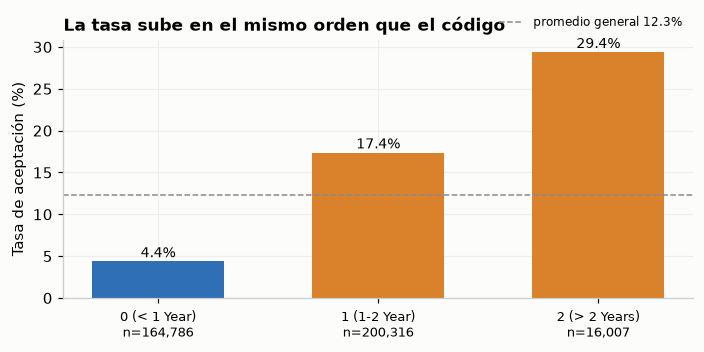

Orden creciente de la tasa confirmado: ['4.4 %', '17.4 %', '29.4 %']


In [4]:
step = cl.encode_vehicle_age(raw)
g = step.groupby("Vehicle_Age")[TARGET].agg(n="size", tasa="mean")
g.index = [f"{k} ({[t for t, c in cl.VEHICLE_AGE_MAP.items() if c == k][0]})" for k in g.index]

fig, ax = plt.subplots(figsize=(6.5, 3.3))
colors = [ORANGE if t > raw[TARGET].mean() else BLUE for t in g["tasa"]]
ax.bar(range(len(g)), g["tasa"] * 100, color=colors, width=0.6)
ax.axhline(raw[TARGET].mean() * 100, color=GRAY, ls="--", lw=1, label=f"promedio general {raw[TARGET].mean():.1%}")
for i, (t, n) in enumerate(zip(g["tasa"], g["n"])):
    ax.text(i, t * 100 + 0.5, f"{t:.1%}", ha="center", fontsize=9)
ax.set_xticks(range(len(g)))
ax.set_xticklabels([f"{i}\nn={n:,}" for i, n in zip(g.index, g["n"])], fontsize=8.5)
ax.set_ylabel("Tasa de aceptación (%)")
ax.set_title("La tasa sube en el mismo orden que el código")
ax.legend(loc="lower right", bbox_to_anchor=(1, 1.0), frameon=False, fontsize=8)
plt.tight_layout()
plt.show()

assert g["tasa"].is_monotonic_increasing, "el orden 0-1-2 no coincide con el orden de la aceptación"
print("Orden creciente de la tasa confirmado:", [pct(t) for t in g["tasa"]])

**Lectura:** la antigüedad del vehículo tiene un **orden natural** y la aceptación lo sigue sin saltarse ningún escalón (4,4 % → 17,4 % → 29,4 %). Por eso es correcto representarla como **0, 1, 2** (un número ordenado) y **no** como tres columnas independientes: se conserva la información de "más antiguo = más aceptación" con una sola columna. Que el orden coincida con la tasa se **comprueba con una afirmación** (`assert`), no a ojo.

### 3.3 `Region_Code` y `Policy_Sales_Channel` · códigos, no cantidades

In [5]:
step = cl.cast_code_columns(raw)
display(pd.DataFrame({
    "tipo antes": raw[cl.CODE_COLUMNS].dtypes.astype(str),
    "tipo después": step[cl.CODE_COLUMNS].dtypes.astype(str),
    "ejemplo antes": [raw[c].iloc[0] for c in cl.CODE_COLUMNS],
    "ejemplo después": [step[c].iloc[0] for c in cl.CODE_COLUMNS],
    "valores distintos antes": [raw[c].nunique() for c in cl.CODE_COLUMNS],
    "valores distintos después": [step[c].nunique() for c in cl.CODE_COLUMNS],
}))

# ¿Tiene sentido el orden numérico del código? Si lo tuviera, a mayor código habría mayor (o menor) aceptación.
rows = []
for c in cl.CODE_COLUMNS:
    g = step.groupby(c)[TARGET].agg(n="size", tasa="mean")
    g = g[g["n"] >= 100]
    rho = spearmanr(g.index, g["tasa"])[0]
    rows.append({"variable": c, "códigos con 100 clientes o más": len(g), "correlación de Spearman entre el número del código y la tasa": round(rho, 3)})
display(pd.DataFrame(rows).set_index("variable"))

,tipo antes,tipo después,ejemplo antes,ejemplo después,valores distintos antes,valores distintos después
Region_Code,float64,int64,28.0,28,53,53
Policy_Sales_Channel,float64,int64,26.0,26,155,155


,códigos con 100 clientes o más,correlación de Spearman entre el número del código y la tasa
variable,,
Region_Code,53,0.034
Policy_Sales_Channel,63,0.113


**Lectura:** la conversión no pierde nada (mismo número de valores distintos). Lo importante es la segunda tabla: la correlación entre **el número del código y la tasa de aceptación** es casi nula (0,03 para región y 0,11 para canal). Es decir, **que la región 28 sea "mayor" que la 3 no significa nada**. Si se dejaran como números, un modelo lineal creería que existe una escala. Por eso en la etapa 4 se tratan como **categorías**. Aquí solo se les quita el decimal, para que `28.0` y `28` no se confundan como categorías distintas.

### 3.4 `Annual_Premium` · marcar el mínimo repetido (sin cambiar la prima)

In [6]:
step = cl.flag_minimum_premium(raw)
flag = step["Premium_is_minimum"]
f, o = step.loc[flag == 1, TARGET], step.loc[flag == 0, TARGET]
diff = f.mean() - o.mean()
se = np.sqrt(f.mean() * (1 - f.mean()) / len(f) + o.mean() * (1 - o.mean()) / len(o))

display(pd.DataFrame({
    "clientes": [len(f), len(o)],
    "% de clientes": [pct(len(f) / len(step)), pct(len(o) / len(step))],
    "tasa de aceptación": [pct(f.mean()), pct(o.mean())],
}, index=[f"prima = {cl.MIN_PREMIUM:,.0f} (marcada)", "otra prima"]))
print(f"Diferencia: {diff * 100:+.2f} puntos porcentuales (intervalo de confianza 95 %: {(diff - 1.96 * se) * 100:+.2f} a {(diff + 1.96 * se) * 100:+.2f}).")

assert (step["Annual_Premium"] == raw["Annual_Premium"]).all(), "la prima no debe cambiar"
print("La columna Annual_Premium quedó idéntica a la original.")

q = raw["Annual_Premium"].quantile([.01, .25, .5, .75, .95, .99, .999, 1.0])
q.index = ["1 %", "25 %", "mediana", "75 %", "95 %", "99 %", "99,9 %", "máximo"]
display(q.rename("prima en ese percentil").to_frame().style.format("{:,.0f}"))

,clientes,% de clientes,tasa de aceptación
"prima = 2,630 (marcada)",64877,17.0 %,13.1 %
otra prima,316232,83.0 %,12.1 %


Diferencia: +1.03 puntos porcentuales (intervalo de confianza 95 %: +0.74 a +1.31).
La columna Annual_Premium quedó idéntica a la original.


,prima en ese percentil
1 %,"2,630"
25 %,"24,405"
mediana,"31,669"
75 %,"39,400"
95 %,"55,176"
99 %,"72,963"
"99,9 %","115,554"
máximo,"540,165"


**Lectura:** el 17 % de los clientes (64.877) tiene exactamente la prima mínima, y es un grupo ligeramente más propenso a aceptar (13,1 % frente a 12,1 %). La diferencia es **real pero pequeña**: el intervalo de confianza (0,7 a 1,3 puntos) **no incluye el cero**, y aun así la correlación con la respuesta es de solo 0,012. Se marca porque es barato y puede ayudar, pero **no se espera que sea una variable importante**.
La prima **no se modifica**: su efecto sobre los modelos se decide en la etapa 4. La tabla de percentiles muestra el problema de fondo: del percentil 99,9 (115.554) al máximo (540.165) hay un salto de casi cinco veces. Esos pocos clientes pesan demasiado en cualquier modelo sensible a los extremos.

### 3.5 Valores imposibles

In [7]:
rules = pd.DataFrame([
    ("Age", f"entre {cl.AGE_RANGE[0]} y {cl.AGE_RANGE[1]}", raw["Age"].min(), raw["Age"].max()),
    ("Driving_License", "solo 0 o 1", raw["Driving_License"].min(), raw["Driving_License"].max()),
    ("Previously_Insured", "solo 0 o 1", raw["Previously_Insured"].min(), raw["Previously_Insured"].max()),
    ("Annual_Premium", "mayor que 0", raw["Annual_Premium"].min(), raw["Annual_Premium"].max()),
    ("Vintage", "0 o más", raw["Vintage"].min(), raw["Vintage"].max()),
], columns=["variable", "regla", "mínimo observado", "máximo observado"]).set_index("variable")
display(rules)

problems = cl.find_impossible_values(raw)
print("Valores imposibles encontrados:", problems if problems else "ninguno")
assert problems == {}

,regla,mínimo observado,máximo observado
variable,,,
Age,entre 18 y 100,20.0,85.0
Driving_License,solo 0 o 1,0.0,1.0
Previously_Insured,solo 0 o 1,0.0,1.0
Annual_Premium,mayor que 0,2630.0,540165.0
Vintage,0 o más,10.0,299.0


Valores imposibles encontrados: ninguno


**Lectura:** ningún valor rompe las reglas. Esto **no es un trámite**: si en el futuro llegaran datos con una edad de 150 o un `Vintage` negativo, `clean()` **se detiene con un error** y dice cuál es el problema, en vez de entrenar un modelo con datos rotos sin que nadie se entere.

## 4. Limpieza completa: `clean()` y su comprobación

`clean()` aplica las cinco reglas en orden. Se verifica que **no se perdió información**: cada conversión es reversible y se puede reconstruir el dato original.

In [8]:
clean_df = cl.clean(raw)

display(pd.DataFrame({"antes": raw.dtypes.astype(str), "después": clean_df.dtypes.astype(str)}).fillna("(columna nueva)"))
mb = lambda d: d.memory_usage(deep=True).sum() / 1e6
print(f"filas: {len(raw):,} -> {len(clean_df):,} | columnas: {raw.shape[1]} -> {clean_df.shape[1]} | memoria: {mb(raw):.1f} MB -> {mb(clean_df):.1f} MB ({1 - mb(clean_df) / mb(raw):.0%} menos)")

inv_damage = clean_df["Vehicle_Damage"].map({v: k for k, v in cl.YES_NO_MAP.items()})
inv_age = clean_df["Vehicle_Age"].map({v: k for k, v in cl.VEHICLE_AGE_MAP.items()})

checks = pd.Series({
    "no se perdieron ni se agregaron filas": len(clean_df) == len(raw),
    "los id siguen siendo los mismos y en el mismo orden": clean_df[ID_COL].equals(raw[ID_COL]),
    "el objetivo no cambió": clean_df[TARGET].equals(raw[TARGET]),
    "Vehicle_Damage se puede reconstruir tal cual": inv_damage.equals(raw["Vehicle_Damage"]),
    "Vehicle_Age se puede reconstruir tal cual": inv_age.equals(raw["Vehicle_Age"]),
    "los códigos de región y canal conservan su valor": bool((clean_df[cl.CODE_COLUMNS].to_numpy() == raw[cl.CODE_COLUMNS].to_numpy()).all()),
    "la prima no cambió": clean_df["Annual_Premium"].equals(raw["Annual_Premium"]),
    "no hay vacíos": int(clean_df.isna().sum().sum()) == 0,
    "no hay columnas con datos personales": not set(cl.PERSONAL_COLUMNS) & set(clean_df.columns),
    "las únicas columnas nuevas son las esperadas": set(clean_df.columns) - set(raw.columns) == {"Premium_is_minimum"},
}, name="¿se cumple?")
display(checks.to_frame())
assert checks.all(), checks[~checks]

,antes,después
Age,int64,int64
Annual_Premium,float64,float64
Driving_License,int64,int64
Gender,str,str
Policy_Sales_Channel,float64,int64
Premium_is_minimum,(columna nueva),int8
Previously_Insured,int64,int64
Region_Code,float64,int64
Response,int64,int64
Vehicle_Age,str,int8


filas: 381,109 -> 381,109 | columnas: 12 -> 13 | memoria: 42.5 MB -> 33.5 MB (21% menos)


,¿se cumple?
no se perdieron ni se agregaron filas,True
los id siguen siendo los mismos y en el mismo orden,True
el objetivo no cambió,True
Vehicle_Damage se puede reconstruir tal cual,True
Vehicle_Age se puede reconstruir tal cual,True
los códigos de región y canal conservan su valor,True
la prima no cambió,True
no hay vacíos,True
no hay columnas con datos personales,True
las únicas columnas nuevas son las esperadas,True


**Lectura:** la limpieza **no pierde información**: de cada columna transformada se recupera el valor original, no cambia ni una fila, el objetivo ni el `id`, y solo agrega una columna (`Premium_is_minimum`). La memoria baja una quinta parte porque los textos y los decimales se convirtieron en enteros pequeños. Cada línea de esta tabla es una **afirmación que haría fallar el notebook** si dejara de cumplirse.

### 4.1 La misma función sobre datos que no ha visto

In [9]:
expected = [c for c in clean_df.columns if c != TARGET]
if TEST_PATH is None:
    kaggle_test = None
    print("No hay test.csv en este repositorio: se omite esta comprobación.")
    print("Alternativa: se aplica clean() a train sin la columna Response, como si fueran datos nuevos.")
    probe = cl.clean(cl.load_raw(TRAIN_PATH).drop(columns=TARGET))
    print("Mismas columnas y en el mismo orden que el entrenamiento (sin Response):", list(probe.columns) == expected)
    print("Tipos iguales a los del entrenamiento:", bool((probe.dtypes == clean_df[expected].dtypes).all()))
else:
    kaggle_test = cl.clean(cl.load_raw(TEST_PATH))
    print(f"{TEST_PATH.name} (sin respuesta): {len(kaggle_test):,} filas, {kaggle_test.shape[1]} columnas.")
    print("Mismas columnas y en el mismo orden que el entrenamiento (sin Response):", list(kaggle_test.columns) == expected)
    print("Tipos iguales a los del entrenamiento:", bool((kaggle_test.dtypes == clean_df[expected].dtypes).all()))

test.csv (sin respuesta): 127,037 filas, 12 columnas.
Mismas columnas y en el mismo orden que el entrenamiento (sin Response): True
Tipos iguales a los del entrenamiento: True


**Lectura:** `clean()` funciona igual con `test.csv`, que **no trae la respuesta**, y entrega las mismas columnas con los mismos tipos. Esto importa porque en producción (la app de Streamlit) los datos nuevos tendrán la misma forma: una función de limpieza que solo sirve para el entrenamiento rompería al predecir.

## 5. Partición: entrenamiento y prueba cerrada

**Unidad de análisis:** un cliente por fila, y el `id` es único (verificado en el EDA y de nuevo cada vez que se parte). Por eso partir **por fila** es válido: ningún cliente puede quedar de los dos lados.
Se **estratifica** por `Response` para que ambos lados tengan la misma proporción de compradores. La **prueba se cierra**: de ella solo se muestran su tamaño y su proporción de compradores (lo mínimo para comprobar la partición); no se mira nada más hasta la etapa de validación final.

In [10]:
train, holdout = sp.split_train_holdout(clean_df)      # 80 / 20, semilla 42, estratificada

summary = pd.DataFrame({
    "clientes": [len(train), len(holdout), len(clean_df)],
    "% del total": [pct(len(train) / len(clean_df)), pct(len(holdout) / len(clean_df)), "100 %"],
    "compradores": [int(train[TARGET].sum()), int(holdout[TARGET].sum()), int(clean_df[TARGET].sum())],
    "tasa de aceptación": [pct(train[TARGET].mean(), 3), pct(holdout[TARGET].mean(), 3), pct(clean_df[TARGET].mean(), 3)],
}, index=["entrenamiento", "prueba (cerrada)", "total"])
display(summary)

sp.assert_unique_ids(clean_df)
sp.assert_disjoint_ids(train, holdout)
assert len(train) + len(holdout) == len(clean_df)
print("Verificado: ningún id está en los dos lados y no se perdió ninguna fila.")

,clientes,% del total,compradores,tasa de aceptación
entrenamiento,304887,80.0 %,37368,12.256 %
prueba (cerrada),76222,20.0 %,9342,12.256 %
total,381109,100 %,46710,12.256 %


Verificado: ningún id está en los dos lados y no se perdió ninguna fila.


**Lectura:** 304.887 clientes para entrenar y 76.222 para la prueba cerrada, con **la misma tasa de aceptación en los tres renglones (12,256 %)**. Esa igualdad no es casualidad: es el efecto de estratificar. Las verificaciones (`assert_unique_ids`, `assert_disjoint_ids`) detienen el notebook si algún día un cliente apareciera en dos filas o en los dos lados.

### 5.1 ¿Cuánto aporta realmente estratificar?

Se compara con la alternativa de **no** estratificar: se reparten los datos al azar 300 veces y se mira cuánto varía la proporción de compradores del lado de prueba. Solo se usa la respuesta de **todo** el conjunto, no se mira la prueba cerrada.

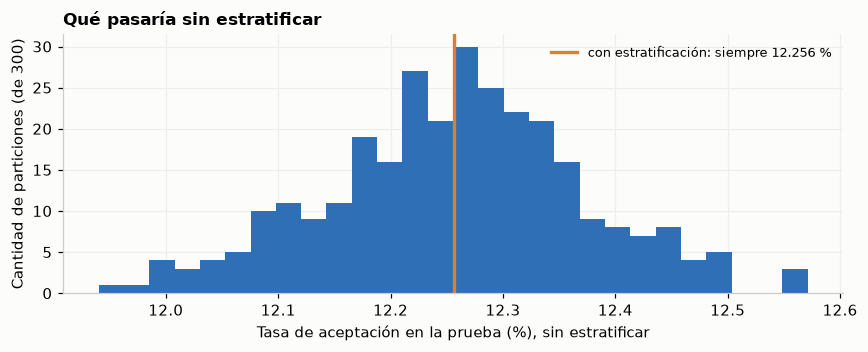

Sin estratificar, la tasa de la prueba oscila entre 11.94 % y 12.57 % (desviación 0.114 puntos).
Con estratificación: 12.256 %, igual que el total (12.256 %).


In [11]:
y_all = clean_df[TARGET].to_numpy()
rates = np.array([train_test_split(y_all, test_size=sp.TEST_SIZE, random_state=i)[1].mean() for i in range(300)])
true_rate = y_all.mean()

fig, ax = plt.subplots(figsize=(8, 3.3))
ax.hist(rates * 100, bins=28, color=BLUE)
ax.axvline(true_rate * 100, color=ORANGE, lw=2.2, label=f"con estratificación: siempre {holdout[TARGET].mean() * 100:.3f} %")
ax.set_xlabel("Tasa de aceptación en la prueba (%), sin estratificar")
ax.set_ylabel("Cantidad de particiones (de 300)")
ax.set_title("Qué pasaría sin estratificar")
ax.legend(frameon=False, fontsize=8.5)
plt.tight_layout()
plt.show()

print(f"Sin estratificar, la tasa de la prueba oscila entre {rates.min() * 100:.2f} % y {rates.max() * 100:.2f} % (desviación {rates.std() * 100:.3f} puntos).")
print(f"Con estratificación: {holdout[TARGET].mean() * 100:.3f} %, igual que el total ({true_rate * 100:.3f} %).")

**Lectura (honesta):** con 76.000 clientes en la prueba, **no estratificar habría movido la tasa solo unas décimas de punto** (entre 11,94 % y 12,57 %). Es decir, aquí estratificar no es una necesidad dramática. Se hace igual porque **es gratis**, hace que todas las métricas sean comparables entre sí, y se vuelve crítico en cuanto se parten subconjuntos pequeños (los pliegues de validación o una prueba más chica), donde el azar sí movería la proporción de forma notable.

## 6. Pliegues de validación (solo dentro del entrenamiento)

La **prueba cerrada no se usa para elegir modelo ni umbral** (`CLAUDE.md`, regla 4). Para eso se usa **validación cruzada** dentro del entrenamiento: se divide en 5 partes; el modelo se entrena con 4 y se evalúa con la quinta, y se rota.

,clientes que entrenan,clientes que validan,compradores al validar,tasa al validar
pliegue,,,,
1,243909,60978,7474,12.257%
2,243909,60978,7474,12.257%
3,243910,60977,7473,12.255%
4,243910,60977,7473,12.255%
5,243910,60977,7474,12.257%


Verificado: cada cliente del entrenamiento se valida exactamente una vez.
Diferencia máxima de tasa entre pliegues: 0.0016 puntos porcentuales.


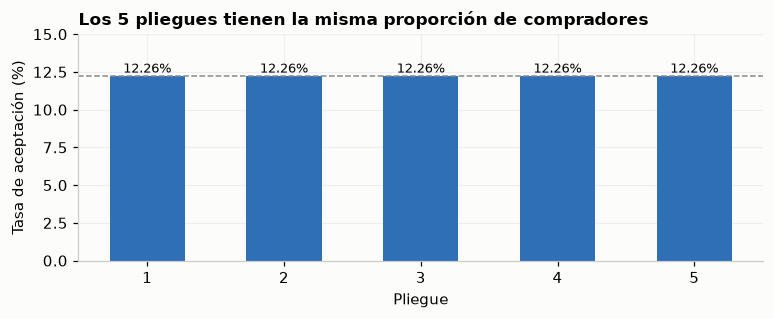

In [12]:
folds = sp.stratified_folds(train, n_splits=5)

rows = []
for i, (tr_idx, va_idx) in enumerate(folds, start=1):
    assert set(tr_idx).isdisjoint(set(va_idx))
    rows.append({"pliegue": i, "clientes que entrenan": len(tr_idx), "clientes que validan": len(va_idx),
                 "compradores al validar": int(train[TARGET].iloc[va_idx].sum()),
                 "tasa al validar": train[TARGET].iloc[va_idx].mean()})
fold_table = pd.DataFrame(rows).set_index("pliegue")
display(fold_table.style.format({"tasa al validar": "{:.3%}"}))

all_validated = np.sort(np.concatenate([va for _, va in folds]))
assert (all_validated == np.arange(len(train))).all()
print("Verificado: cada cliente del entrenamiento se valida exactamente una vez.")
print(f"Diferencia máxima de tasa entre pliegues: {(fold_table['tasa al validar'].max() - fold_table['tasa al validar'].min()) * 100:.4f} puntos porcentuales.")

fig, ax = plt.subplots(figsize=(7, 3))
ax.bar(fold_table.index.astype(str), fold_table["tasa al validar"] * 100, color=BLUE, width=0.55)
ax.axhline(train[TARGET].mean() * 100, color=GRAY, ls="--", lw=1)
for i, t in enumerate(fold_table["tasa al validar"]):
    ax.text(i, t * 100 + 0.2, f"{t:.2%}", ha="center", fontsize=8.5)
ax.set_ylim(0, 15)
ax.set_xlabel("Pliegue")
ax.set_ylabel("Tasa de aceptación (%)")
ax.set_title("Los 5 pliegues tienen la misma proporción de compradores")
plt.tight_layout()
plt.show()

**Lectura:** los cinco pliegues validan con 60.977-60.978 clientes y **7.473-7.474 compradores cada uno**. Como son prácticamente idénticos, las diferencias de métricas entre pliegues se deberán al modelo y no a que a un pliegue le tocaron más compradores. Esa estabilidad es lo que permite comparar modelos con justicia en el torneo de la etapa 5.

## 7. Anticipo de la etapa 4: lo que se mide hoy para decidir mañana

Estas decisiones **no se aplican aquí** (dependen del entrenamiento), pero sí se **miden solo con el entrenamiento**, para saber qué esperar. La prueba cerrada no interviene.

### 7.1 Canales de venta raros

Canales en el entrenamiento: 154. Con menos de 100 clientes: 99 (64% de los canales).
Esos 99 canales raros suman solo 2,231 clientes: 0.73% del entrenamiento.
En test.csv (clientes a predecir): 2 filas (0.002%) vienen de un canal que el entrenamiento nunca vio, y 911 (0.72%) de un canal raro.
Regiones desconocidas en test.csv: 0


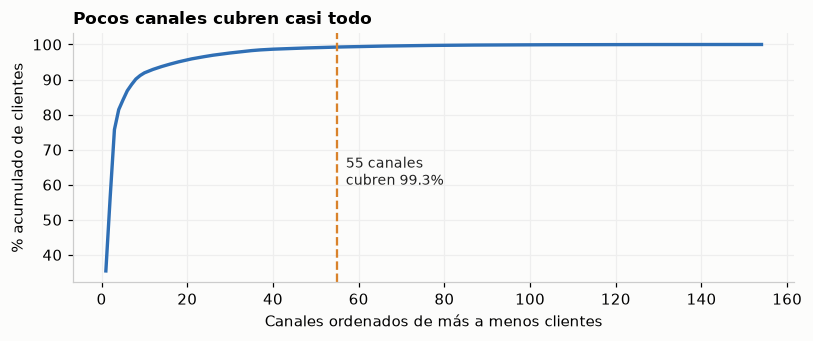

In [13]:
ch = train["Policy_Sales_Channel"].value_counts()
rare = ch[ch < 100]
print(f"Canales en el entrenamiento: {len(ch)}. Con menos de 100 clientes: {len(rare)} ({len(rare) / len(ch):.0%} de los canales).")
print(f"Esos {len(rare)} canales raros suman solo {rare.sum():,} clientes: {rare.sum() / len(train):.2%} del entrenamiento.")

region_known = set(train["Region_Code"].unique())
chan_known = set(ch.index)
if kaggle_test is not None:
    unseen_ch = ~kaggle_test["Policy_Sales_Channel"].isin(chan_known)
    rare_ch = kaggle_test["Policy_Sales_Channel"].isin(set(rare.index))
    print(f"En test.csv (clientes a predecir): {unseen_ch.sum()} filas ({unseen_ch.mean():.3%}) vienen de un canal que el entrenamiento nunca vio, "
          f"y {rare_ch.sum():,} ({rare_ch.mean():.2%}) de un canal raro.")
    print(f"Regiones desconocidas en test.csv: {(~kaggle_test['Region_Code'].isin(region_known)).sum()}")
else:
    print("Sin test.csv no se puede medir cuántos clientes a predecir caen en canales desconocidos o raros.")

cum = ch.sort_values(ascending=False).cumsum() / len(train)
fig, ax = plt.subplots(figsize=(7.5, 3.2))
ax.plot(range(1, len(cum) + 1), cum.to_numpy() * 100, color=BLUE, lw=2.2)
ax.axvline(len(ch) - len(rare), color=ORANGE, ls="--", lw=1.5)
ax.text(len(ch) - len(rare) + 2, 60, f"{len(ch) - len(rare)} canales\ncubren {(1 - rare.sum() / len(train)):.1%}", color=INK, fontsize=9)
ax.set_xlabel("Canales ordenados de más a menos clientes")
ax.set_ylabel("% acumulado de clientes")
ax.set_title("Pocos canales cubren casi todo")
plt.tight_layout()
plt.show()

**Lectura:** hay **99 canales raros (64 % de los canales)** y juntos suman apenas **0,73 % de los clientes**. Esto cambia la urgencia: agrupar los canales raros en "otros" reduce mucho el número de categorías (de 154 a unas 56) con un costo mínimo, y evita que el modelo memorice canales de 5 o 10 clientes. Pero **no es una decisión que cambie las métricas de forma grande**. Además, solo 2 filas de `test.csv` tienen un canal que el entrenamiento nunca vio: la regla de "canal desconocido → otros" debe existir en el `Pipeline`, aunque hoy afecte a casi nadie.

### 7.2 La prima y sus extremos

,asimetría (0 = simétrica)
original,1.72
"recortada en el percentil 99 (73,132)",-0.17
logaritmo,-1.47


El percentil 99 se calculó solo con el entrenamiento; deja 1.0% de los clientes por encima.


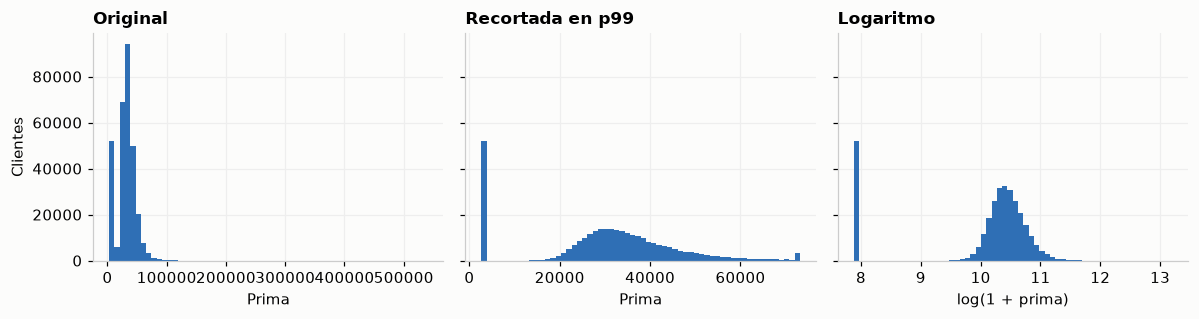

In [14]:
a = train["Annual_Premium"]
p99 = a.quantile(0.99)
variants = pd.Series({
    "original": skew(a),
    f"recortada en el percentil 99 ({p99:,.0f})": skew(a.clip(upper=p99)),
    "logaritmo": skew(np.log1p(a)),
}, name="asimetría (0 = simétrica)")
display(variants.round(2).to_frame())
print(f"El percentil 99 se calculó solo con el entrenamiento; deja {(a > p99).mean():.1%} de los clientes por encima.")

fig, axes = plt.subplots(1, 3, figsize=(11, 3), sharey=True)
for ax, (title, values) in zip(axes, [("Original", a), ("Recortada en p99", a.clip(upper=p99)), ("Logaritmo", np.log1p(a))]):
    ax.hist(values, bins=60, color=BLUE)
    ax.set_title(title)
    ax.set_xlabel("Prima" if title != "Logaritmo" else "log(1 + prima)")
axes[0].set_ylabel("Clientes")
plt.tight_layout()
plt.show()

**Lectura:** la prima original es **muy asimétrica** (1,72: cola larga hacia valores altos). **Recortarla en el percentil 99 la deja casi simétrica (-0,17)**; en cambio el **logaritmo la sobrecorrige (-1,47)** porque el pico de 2.630 queda como una cola larga a la izquierda. Es un hallazgo útil: **el recorte funciona mejor que el logaritmo para esta variable**. Recuerda que el percentil 99 debe calcularse **dentro del `Pipeline`, solo con los datos de entrenamiento**: si se calculara aquí con todos los datos, la prueba influiría en el ajuste.

### 7.3 Relaciones entre variables ya limpias

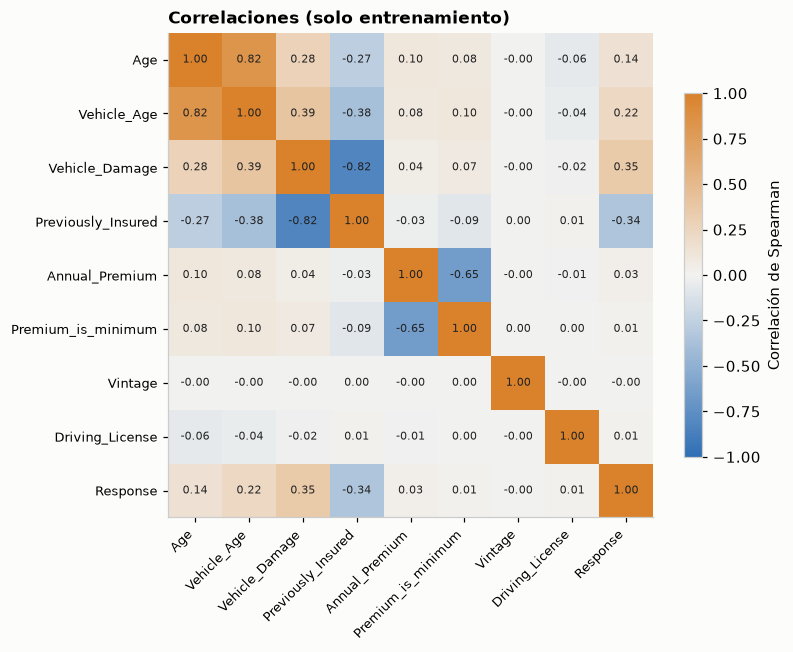

Correlación de cada variable con la respuesta:


,Spearman con Response
Vehicle_Damage,0.354
Previously_Insured,-0.341
Vehicle_Age,0.220
Age,0.144
Annual_Premium,0.034
Premium_is_minimum,0.012
Driving_License,0.010
Vintage,-0.002


In [15]:
num_cols = ["Age", "Vehicle_Age", "Vehicle_Damage", "Previously_Insured", "Annual_Premium", "Premium_is_minimum", "Vintage", "Driving_License", TARGET]
corr = train[num_cols].corr(method="spearman")

cmap = LinearSegmentedColormap.from_list("div", [BLUE, "#f2f2f0", ORANGE])
fig, ax = plt.subplots(figsize=(7.4, 6))
im = ax.imshow(corr, cmap=cmap, vmin=-1, vmax=1)
ax.set_xticks(range(len(num_cols)))
ax.set_yticks(range(len(num_cols)))
ax.set_xticklabels(num_cols, rotation=45, ha="right", fontsize=8.5)
ax.set_yticklabels(num_cols, fontsize=8.5)
ax.grid(False)
for i in range(len(num_cols)):
    for j in range(len(num_cols)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7.5, color=INK)
fig.colorbar(im, ax=ax, shrink=0.75, label="Correlación de Spearman")
ax.set_title("Correlaciones (solo entrenamiento)")
plt.tight_layout()
plt.show()

print("Correlación de cada variable con la respuesta:")
display(corr[TARGET].drop(TARGET).sort_values(key=abs, ascending=False).round(3).to_frame("Spearman con Response"))

**Lectura:**
- **`Previously_Insured` y `Vehicle_Damage` están fuertemente relacionadas entre sí (-0,82):** quien ya tiene seguro casi nunca tuvo daño y viceversa. Para un modelo lineal esto es **multicolinealidad**: las dos dicen casi lo mismo y sus coeficientes serán inestables. Con árboles o *boosting* no es problema. Es un argumento para probar modelos de árboles en el torneo.
- **`Age` y `Vehicle_Age` también van juntas (0,82):** los clientes jóvenes tienen vehículos más nuevos, y los mayores, más viejos. Esto **matiza el EDA**: parte del efecto que se atribuía a la antigüedad del vehículo puede ser, en realidad, efecto de la edad del cliente (o al revés). Un modelo lineal no podrá separar bien cada aporte; hay que vigilarlo al interpretar la importancia de variables en la etapa 7.
- **`Annual_Premium` y `Premium_is_minimum` (-0,65)** se relacionan por construcción: la marca vale 1 justo en el extremo bajo de la prima. No es un hallazgo, es la consecuencia esperada de haberla creado.
- **Las correlaciones con la respuesta confirman el orden del EDA:** `Vehicle_Damage` (+0,35) y `Previously_Insured` (-0,34) lideran; luego `Vehicle_Age` (+0,22) y `Age` (+0,14). `Annual_Premium` (0,03), `Premium_is_minimum` (0,01), `Driving_License` (0,01) y `Vintage` (-0,002) casi no se relacionan.
- Ojo: Spearman mide relaciones **crecientes o decrecientes**. La edad tiene forma de campana, así que su correlación (0,14) **subestima** lo útil que es, como se vio en el EDA.

## 8. Guardar los datos de la etapa

Se guardan en `data/processed/` (**no se versionan en Git**: se regeneran ejecutando este notebook). Se usa el formato *parquet*, que conserva los tipos (enteros, enteros pequeños) sin ambigüedades. La prueba queda guardada y **cerrada hasta la etapa 7**.

In [16]:
PROCESSED.mkdir(parents=True, exist_ok=True)
train.to_parquet(PROCESSED / "train.parquet", index=False)
holdout.to_parquet(PROCESSED / "holdout.parquet", index=False)

# Lo guardado debe ser idéntico a lo que hay en memoria
pd.testing.assert_frame_equal(pd.read_parquet(PROCESSED / "train.parquet"), train)
pd.testing.assert_frame_equal(pd.read_parquet(PROCESSED / "holdout.parquet"), holdout)

display(pd.DataFrame({
    "archivo": ["train.parquet", "holdout.parquet"],
    "filas": [len(train), len(holdout)],
    "tamaño (MB)": [round((PROCESSED / f).stat().st_size / 1e6, 1) for f in ["train.parquet", "holdout.parquet"]],
}).set_index("archivo"))
print("Releídos desde disco y comparados con la memoria: idénticos.")

,filas,tamaño (MB)
archivo,,
train.parquet,304887,3.9
holdout.parquet,76222,1.2


Releídos desde disco y comparados con la memoria: idénticos.


## 9. Comprobaciones finales

### 9.1 `data/raw/` no cambió

In [17]:
hash_after = {p.name: sha256(p) for p in raw_files}
result = pd.DataFrame({"huella antes": [hash_before[k][:16] + "…" for k in hash_before],
                       "huella después": [hash_after[k][:16] + "…" for k in hash_before],
                       "idéntica": [hash_before[k] == hash_after[k] for k in hash_before]}, index=list(hash_before))
display(result)
assert hash_before == hash_after

,huella antes,huella después,idéntica
train.csv,3b60d10728517563…,3b60d10728517563…,True
test.csv,c6a181deaec964fc…,c6a181deaec964fc…,True


### 9.2 Las pruebas automáticas

In [18]:
res = subprocess.run([sys.executable, "-m", "pytest", "-q", "-p", "no:cacheprovider", "--color=no", "tests/test_cleaning.py", "tests/test_split.py"],
                     cwd=ROOT, capture_output=True, text=True)
print(res.stdout.strip().splitlines()[-1])
assert res.returncode == 0, res.stdout[-2000:]

26 passed in 6.46s


## 10. Qué se aprendió y qué sigue

| # | Hallazgo | Consecuencia |
|---|---|---|
| 1 | La limpieza es una **traducción sin pérdida**: cada conversión se puede revertir y no cambia filas, objetivo ni `id` | Se puede confiar en que los datos limpios representan a los originales |
| 2 | El orden de `Vehicle_Age` coincide con el de la aceptación (4,4 % → 17,4 % → 29,4 %) | Se codifica como 0-1-2 y no como categorías separadas |
| 3 | El número de un código de región o canal **no significa nada** (correlación 0,03 y 0,11) | Son **categorías**: se codifican en la etapa 4 |
| 4 | El 17 % con prima mínima acepta algo más (+1,0 pp), pero su efecto es pequeño (correlación 0,012) | Se marca; no se espera que sea clave |
| 5 | Estratificar mueve poco la proporción aquí (±0,1 pp) pero es gratis y garantiza pliegues idénticos (7.473-7.474 compradores cada uno) | Comparaciones justas en el torneo |
| 6 | Los 99 canales raros suman solo 0,73 % de los clientes | Agruparlos baja las categorías de 154 a ≈ 56 casi sin costo; **no es una decisión crítica** |
| 7 | El recorte de la prima en el percentil 99 deja la distribución casi simétrica; el logaritmo la sobrecorrige | Recortar dentro del `Pipeline`, con el percentil del entrenamiento |
| 8 | `Previously_Insured` y `Vehicle_Damage` se parecen mucho (-0,82), y `Age` con `Vehicle_Age` también (0,82) | Preferir modelos de árboles o vigilar la colinealidad en modelos lineales; cuidar la interpretación de importancias |

**Hallazgo que no esperábamos:** estratificar casi no cambia la proporción de compradores con 76.000 clientes en la prueba; el beneficio es de **garantía y comparabilidad**, no de corregir un problema grande.

**Lo que este notebook NO hace (y por qué):** recortar, escalar, codificar, agrupar categorías raras ni imputar. Todo eso depende de los datos de entrenamiento y va dentro del `Pipeline` de la etapa 4.

## Entregable de esta etapa (hito H1)

- [x] La limpieza corre de principio a fin desde el repo.
- [x] La partición respeta la unidad de análisis (un cliente por fila) y está **verificada con pruebas**.
- [x] `pytest` en verde (26 pruebas de limpieza y partición).
- [x] `data/raw/` no cambió (huella SHA-256 igual).
- [x] Prueba guardada y sin mirar.
- [ ] El grupo revisa las hipótesis y aprueba la especificación `especificaciones/03-preprocesamiento.md`.
- [ ] Revisión del código con `material-del-curso/kit/checklist-revision-ia.md`; cada integrante puede explicar una función.
- [ ] Subir todo a GitHub.

**Siguiente:** `04_features.ipynb`.